# 2. Decision Tree: Predicting Heart Disease

**Dataset documentation:** https://archive.ics.uci.edu/dataset/45/heart+disease
**Data file:** `data/heart.csv` (the Cleveland subset of the UCI Heart Disease data, 303 patients, 13 clinical features)

## 2.1 Objectives (Business Understanding)

**Business problem:** A cardiology clinic wants to decide which patients should get further, expensive tests (like angiography) first. If routine measurements could flag likely heart disease, that would help them prioritise.

**What I am predicting:** whether a patient has heart disease.

**Target variable:** `disease` (1 = heart disease present, 0 = absent). I create it from the file's `target` column, see the note in 2.2.
**Predictors:** 13 clinical features: age, sex, chest-pain type (`cp`), resting blood pressure (`trestbps`), cholesterol (`chol`), fasting blood sugar (`fbs`), resting ECG (`restecg`), maximum heart rate (`thalach`), exercise angina (`exang`), ST depression (`oldpeak`), ST slope (`slope`), number of major vessels (`ca`) and thalassemia result (`thal`).
**What counts as success:** test accuracy clearly above the majority-class baseline, and decent recall on the disease class, because missing a sick patient is worse than doing one extra check on a healthy patient. I would also like a tree small enough for a doctor to read.

## 2.2 Data Exploration (Data Understanding & Preparation)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

os.makedirs('plots', exist_ok=True)
df = pd.read_csv('data/heart.csv')
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


**What I see:** 303 patients, 13 features plus the target, all numeric. Categorical variables such as `sex`, `cp`, `restecg`, `slope` and `thal` are stored as integer codes. This CSV is a re-coded copy of the UCI Cleveland data, so some code values don't match the UCI documentation page.

In [2]:
print('Missing values:', df.isna().sum().sum(), '| Duplicate rows:', df.duplicated().sum())
print(df.groupby('target')[['thalach', 'oldpeak', 'exang', 'ca']].mean().round(2))

Missing values: 0 | Duplicate rows: 1
        thalach  oldpeak  exang    ca
target                               
0        139.10     1.59   0.55  1.17
1        158.47     0.58   0.14  0.36


**Data problem I found:** no missing values and one duplicate row, which I remove. More importantly, the group averages show that `target = 1` patients have a *higher* maximum heart rate and *much lower* ST depression, angina and vessel counts. That looks like healthy patients, so in this file `target = 1` must mean *no disease*. To avoid predicting the wrong thing, I create `disease = 1 - target`, so 1 means disease present.

In [3]:
df = df.drop_duplicates().copy()
df['disease'] = 1 - df['target']      # 1 = heart disease present, 0 = absent
df = df.drop(columns='target')
print(df['disease'].value_counts())
print(df.shape)

disease
0    164
1    138
Name: count, dtype: int64
(302, 14)


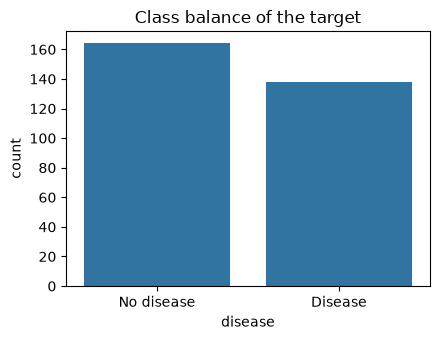

In [4]:
plt.figure(figsize=(4.5, 3.5))
sns.countplot(data=df, x='disease')
plt.xticks([0, 1], ['No disease', 'Disease']); plt.title('Class balance of the target')
plt.tight_layout(); plt.savefig('plots/2_class_balance.png', dpi=120); plt.show()

**What I see:** after removing the duplicate there are 302 patients, 164 healthy (54%) and 138 with disease (46%). The classes are fairly balanced, so accuracy is a fair metric and I don't need resampling. A model that always says "no disease" would get about 54%, so that is the number to beat.

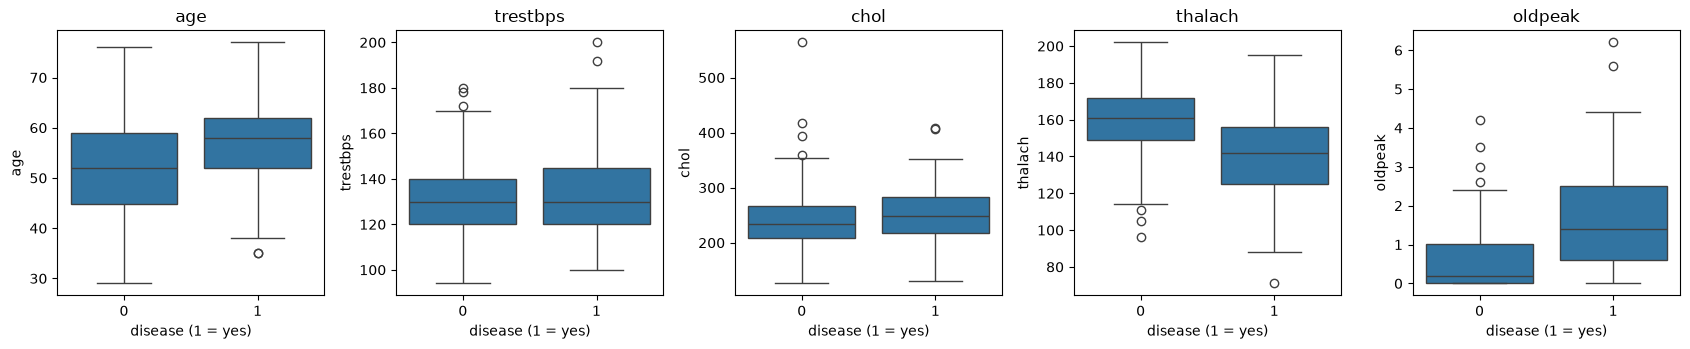

In [5]:
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
for a, c in zip(ax, num_cols):
    sns.boxplot(data=df, x='disease', y=c, ax=a); a.set_title(c); a.set_xlabel('disease (1 = yes)')
plt.tight_layout(); plt.savefig('plots/2_numeric_boxplots.png', dpi=120); plt.show()

**What I see:** patients with disease have a lower maximum heart rate (`thalach`, median 142 vs 161), a higher ST depression (`oldpeak`, median 1.4 vs 0.2) and are a bit older (58 vs 52). Cholesterol and resting blood pressure overlap a lot between the two groups, so they look weak on their own. There are a few high cholesterol outliers, but I keep them because trees (and kNN after scaling) can handle them.

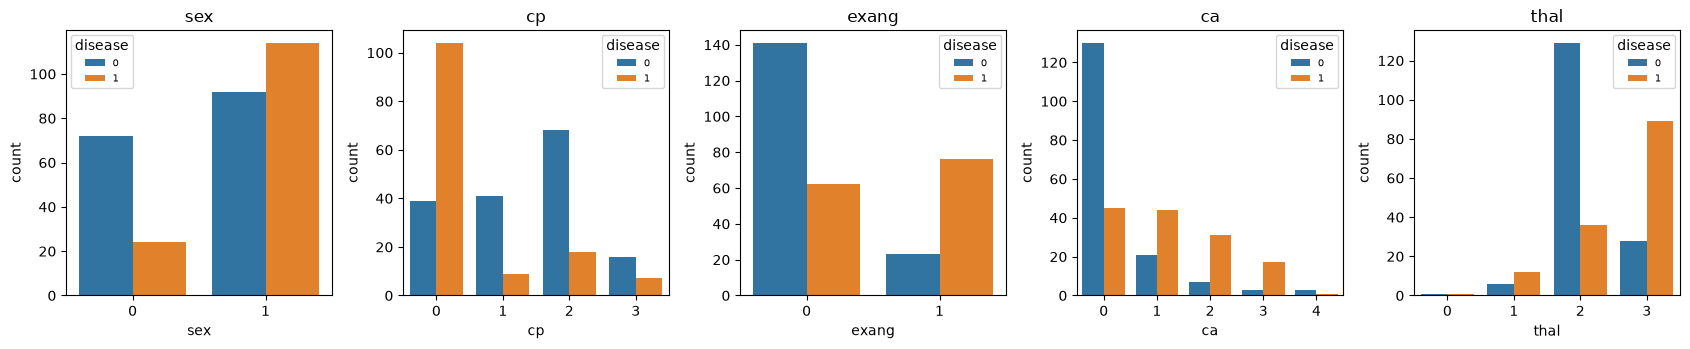

In [6]:
cat_cols = ['sex', 'cp', 'exang', 'ca', 'thal']
fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
for a, c in zip(ax, cat_cols):
    sns.countplot(data=df, x=c, hue='disease', ax=a); a.set_title(c); a.legend(title='disease', fontsize=7)
plt.tight_layout(); plt.savefig('plots/2_categorical_counts.png', dpi=120); plt.show()

**What I see:** disease is much more common in men (55% vs 25% in women), in patients with exercise angina (77% vs 31%), and when more major vessels are coloured (`ca`: 26% at 0 vessels, over 80% at 2 to 3). `thal` code 2 is mostly healthy (22% disease) while code 3 is mostly disease (76%). Chest-pain code 0 has by far the highest disease rate (73%, against 18 to 30% for the other codes).

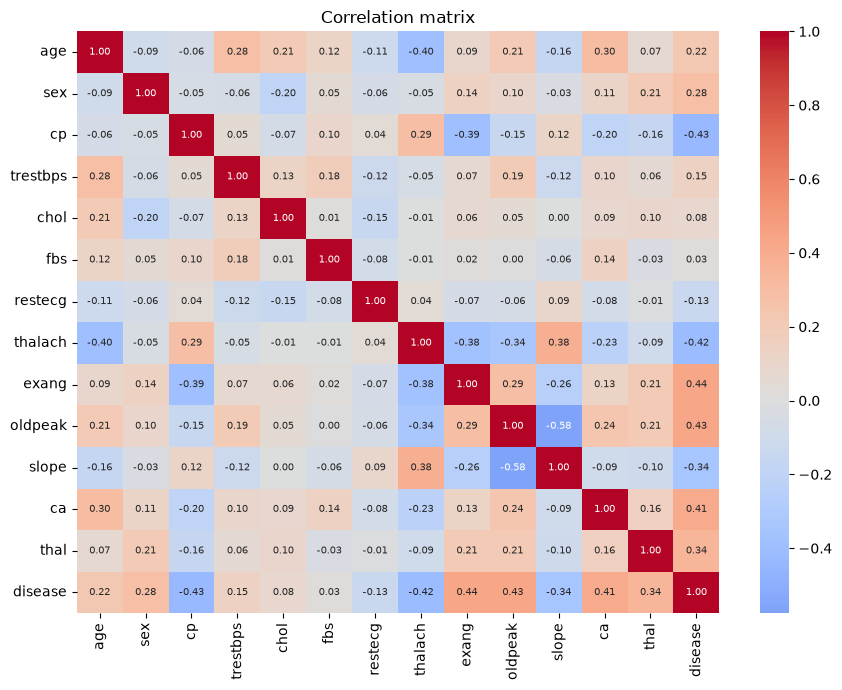

In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Correlation matrix'); plt.tight_layout(); plt.savefig('plots/2_correlation_heatmap.png', dpi=120); plt.show()

**What I see:** the strongest correlations with `disease` are `exang` (+0.44), `oldpeak` (+0.43), `ca` (+0.41), `cp` (-0.43) and `thalach` (-0.42). No two predictors are extremely correlated, so redundancy is not a problem. `fbs` (0.03) and `chol` (0.08) have almost no link with the target. Correlation for integer-coded categories like `cp` is only a rough guide.

## 2.3 Modeling

In [8]:
X = df.drop(columns='disease')
y = df['disease']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

# Baseline: an unrestricted tree
full = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print('Unrestricted tree -> depth:', full.get_depth(), '| leaves:', full.get_n_leaves())
print('Train accuracy:', round(full.score(X_train, y_train), 3),
      '| 5-fold CV accuracy:', round(cross_val_score(full, X_train, y_train, cv=5).mean(), 3))

Train: (241, 13)  Test: (61, 13)
Unrestricted tree -> depth: 11 | leaves: 44
Train accuracy: 1.0 | 5-fold CV accuracy: 0.751


**What I see:** the tree with no limits grows to depth 11 with 44 leaves. It gets 100% on the training data but only about 75% in cross-validation, so it is clearly overfitting. I need to limit the size of the tree.

Best parameters: {'max_depth': 4, 'min_samples_leaf': 5}
Best CV accuracy: 0.813


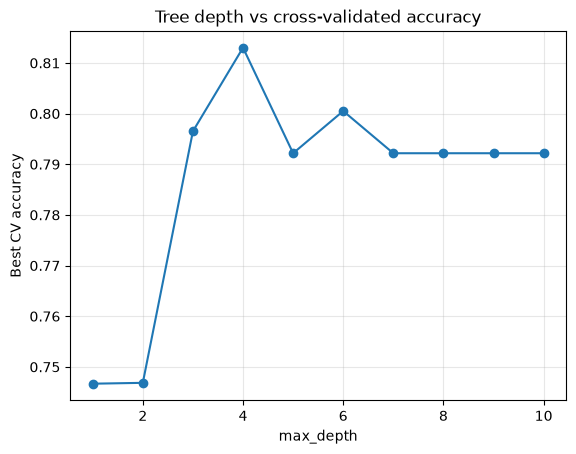

In [9]:
# Tune tree size with 5-fold cross validation
param_grid = {'max_depth': range(1, 11), 'min_samples_leaf': [1, 3, 5, 10]}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)
print('Best parameters:', grid.best_params_)
print('Best CV accuracy:', round(grid.best_score_, 3))

cv_depth = pd.DataFrame(grid.cv_results_).groupby('param_max_depth')['mean_test_score'].max()
plt.plot(cv_depth.index.astype(int), cv_depth.values, marker='o')
plt.xlabel('max_depth'); plt.ylabel('Best CV accuracy'); plt.title('Tree depth vs cross-validated accuracy'); plt.grid(alpha=.3)
plt.savefig('plots/2_depth_vs_cv.png', dpi=120); plt.show()

**What I see:** cross-validated accuracy goes up until depth 4 and then drops and stays flat, because deeper trees start to fit noise. The grid search picks `max_depth = 4` with `min_samples_leaf = 5` (CV accuracy 0.813). The leaf size makes sure each leaf covers enough patients to be reliable.

Final tree -> depth: 4 | leaves: 13


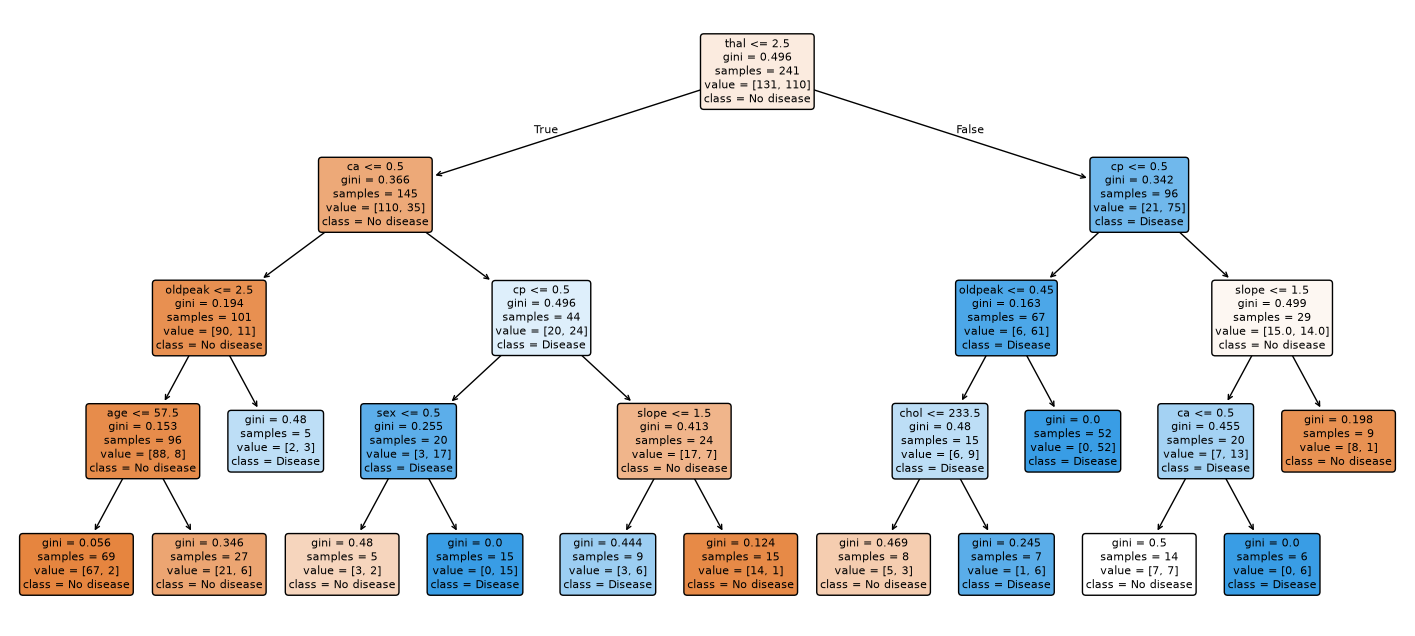

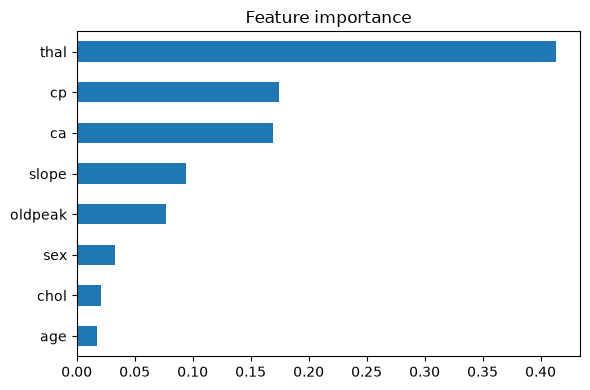

thal       0.413
cp         0.174
ca         0.169
slope      0.094
oldpeak    0.077
sex        0.033
dtype: float64


In [10]:
tree = grid.best_estimator_
print('Final tree -> depth:', tree.get_depth(), '| leaves:', tree.get_n_leaves())
plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=X.columns, class_names=['No disease', 'Disease'], filled=True, rounded=True, fontsize=8)
plt.savefig('plots/2_decision_tree.png', dpi=120, bbox_inches='tight'); plt.show()

imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
imp[imp > 0].plot.barh(figsize=(6, 4)).invert_yaxis(); plt.title('Feature importance')
plt.tight_layout(); plt.savefig('plots/2_feature_importance.png', dpi=120); plt.show()
print(imp.round(3).head(6))

**What I see:** the final tree has depth 4 and 13 leaves, so it is small enough to read. The first split uses `thal`, which is also the most important feature (about 41% of the importance), followed by chest-pain type `cp` and number of major vessels `ca`. `slope` and `oldpeak` add a bit more. This fits what I saw in the exploration, where `thal`, `cp` and `ca` separated the classes best.

## 2.4 Evaluation & Conclusion

Test accuracy: 0.738
Majority-class baseline: 0.541
              precision    recall  f1-score   support

  No disease       0.72      0.85      0.78        33
     Disease       0.77      0.61      0.68        28

    accuracy                           0.74        61
   macro avg       0.75      0.73      0.73        61
weighted avg       0.74      0.74      0.73        61



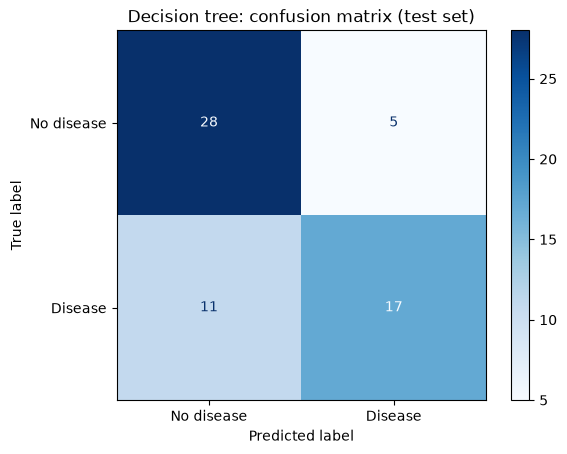

In [11]:
pred = tree.predict(X_test)
print('Test accuracy:', round(accuracy_score(y_test, pred), 3))
print('Majority-class baseline:', round(max(y_test.mean(), 1 - y_test.mean()), 3))
print(classification_report(y_test, pred, target_names=['No disease', 'Disease']))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['No disease', 'Disease']).plot(cmap='Blues')
plt.title('Decision tree: confusion matrix (test set)'); plt.savefig('plots/2_confusion_matrix.png', dpi=120); plt.show()

### Evaluation
- Test accuracy is **0.738** (45 of 61 correct), against a baseline of 0.541 for always predicting the majority class.
- For the disease class, precision is 0.77 and **recall is 0.61**. For the healthy class, precision is 0.72 and recall is 0.85.
- In the confusion matrix, 11 of the 28 patients with disease were missed (false negatives).

### Conclusion
The tuned tree beats the baseline by about 20 percentage points using only a few readable rules, and the main drivers (`thal`, `cp`, `ca`) make sense medically. But a recall of 61% means it misses around 4 in 10 sick patients, so I don't think it is good enough to use alone for screening. Test accuracy (0.74) is also lower than the CV accuracy from tuning (0.81). I think there are two reasons: picking parameters using CV scores is a bit optimistic, and a test set of 61 patients is small (one patient is about 1.6 percentage points). I would call it a transparent decision-support tool, not a diagnosis tool. In Section 3 I check if kNN does better.